# Filler Strategy Lab

*An exploration of decision strategies in a competitive territory-capture game.*

After losing a few too many games of Filler to a friend, I started wondering whether I was making poor decisions or simply failing to think far enough ahead. This project turns that question into a mathematical experiment: model the game, compare four decision rules, and see how they perform under the same starting conditions.

## 1. Research questions and game rules

Does accounting for future territory and the opponent's possible responses improve performance over maximizing the number of tiles captured on the current turn? Does looking further ahead consistently improve outcomes? How do turn order, stopping rules, and the weights influence performance?

Two players start in opposite corners of a 7 × 8 grid with six colors. On each turn, a player chooses a color other than either player's current color, recolors their territory, and acquires connected unclaimed tiles of that color. Owned tiles cannot be taken by the opponent. When all tiles are claimed, the player with more tiles wins; equal scores constitute a tie.

This is an independent model inspired by Filler. Moves that capture no tiles are allowed. Because repeated color changes can prevent a game from ending, I classify a game as a draw after 12 consecutive moves without a capture. This is a modeling convention, not a verified rule of the original game.

**Reproduction:** run all cells from the repository directory using Python 3.10 or newer, pandas, and Matplotlib. Node.js is optional for the browser agreement check. `games.csv` contains the original 1,024 game records. The remaining experiments are regenerated in the notebook.

## 2. Mathematical representation of the game

### 2.1 Board, territory, and legal decisions

Let $G=(V,E)$ denote the grid graph, where each vertex represents a tile and an edge connects horizontally or vertically adjacent tiles. Let $c(v)$ be the original color of tile $v$ and $\mathcal{C}$ the set of six colors.

At any stage, the state is

$$
s=(S_1,S_2,c_1,c_2,p,z),
$$

where $S_i$ is the territory owned by player $i$, $c_i$ is that player's current color, $p$ identifies whose turn it is, and $z$ counts consecutive moves without a capture. The territories are disjoint. Unclaimed tiles and legal colors at a nonterminal state are

$$
N(s)=V\setminus(S_1\cup S_2),\qquad A(s)=\mathcal{C}\setminus\{c_1,c_2\}.
$$

Each decision consists of choosing one of four colors. Once the board and decision are specified, the next state is deterministic.

### 2.2 Capturing territory

For a legal color $a$, let $C_a=\{v\in N(s):c(v)=a\}$. Starting from $X_0=S_p$, expand the current player's territory repeatedly using

$$
X_{k+1}=X_k\cup\bigl(\Gamma(X_k)\cap C_a\bigr),
$$

where $\Gamma(X)$ is the set of all tiles adjacent to at least one tile in $X$. Stop when $X_{k+1}=X_k$. The resulting set is the new territory. Write $T(s,a)$ for the resulting state, including the change of turn and updated no-capture count.

In Python, tile sets are stored as integer masks: a tile is present when its corresponding binary digit is one. This allows set operations to be computed directly. The code uses zero-based indexing (`p0` and `p1` correspond to Players 1 and 2 in the equations).

The seeded board generator excludes identical horizontal or vertical neighbors and ensures that starting colors differ. The same seed reproduces the board in the browser.

In [1]:
"""Reference implementation. Bit i denotes row-major tile i; colors 0..5.

Rules: orthogonal adjacency, transitive captures, immutable neutral colors,
no stealing, current and opponent colors unavailable. Noncapturing moves are
allowed. A 12-consecutive-noncapture draw cutoff is a documented simulation rule.
"""
from dataclasses import dataclass
from random import Random

COLORS = 'BRGYKP'
STALL_LIMIT = 12
WEIGHTS = (10, 2, 4, 1)

@dataclass(frozen=True, slots=True)
class Board:
    rows: int
    cols: int
    colors: tuple[int, ...]
    masks: tuple[int, ...] = ()
    full: int = 0
    left: int = 0
    right: int = 0

    def __post_init__(self):
        if not (2 <= self.rows <= 10 and 2 <= self.cols <= 10):
            raise ValueError('Board dimensions must be between 2 and 10')
        colors = tuple(self.colors)
        if len(colors) != self.rows * self.cols or any(not isinstance(c, int) or not 0 <= c < 6 for c in colors):
            raise ValueError('Expected rows × cols colors in 0..5')
        if colors[(self.rows - 1) * self.cols] == colors[self.cols - 1]:
            raise ValueError('Starting corner colors must differ')
        object.__setattr__(self, 'colors', colors)
        object.__setattr__(self, 'masks', tuple(sum(1 << i for i, c in enumerate(colors) if c == k) for k in range(6)))
        object.__setattr__(self, 'full', (1 << len(colors)) - 1)
        object.__setattr__(self, 'left', sum(1 << (r*self.cols) for r in range(self.rows)))
        object.__setattr__(self, 'right', self.left << (self.cols - 1))

    def neighbors(self, bits):
        return (((bits & ~self.left) >> 1) | ((bits & ~self.right) << 1) |
                (bits >> self.cols) | (bits << self.cols)) & self.full

@dataclass(frozen=True, slots=True)
class State:
    p0: int
    p1: int
    c0: int
    c1: int
    turn: int = 0
    stalls: int = 0

    @property
    def owned(self):
        return self.p0, self.p1

    @property
    def colors(self):
        return self.c0, self.c1


def generate_board(rows=7, cols=8, seed=1):
    """Portable xorshift32 generator; excludes left/up colors and matching corners."""
    if not (2 <= rows <= 10 and 2 <= cols <= 10):
        raise ValueError('Board dimensions must be between 2 and 10')
    x = int(seed) & 0xffffffff or 0x9e3779b9
    values = []
    for i in range(rows*cols):
        r, c = divmod(i, cols)
        banned = set()
        if r: banned.add(values[i-cols])
        if c: banned.add(values[i-1])
        if i == (rows-1)*cols: banned.add(values[cols-1])
        choices = [k for k in range(6) if k not in banned]
        x ^= (x << 13) & 0xffffffff
        x ^= x >> 17
        x ^= (x << 5) & 0xffffffff
        x &= 0xffffffff
        values.append(choices[x % len(choices)])
    return Board(rows, cols, tuple(values))


def new_game(board, first=0):
    if first not in (0,1): raise ValueError('Invalid first player')
    a, b = (board.rows - 1) * board.cols, board.cols - 1
    return State(1 << a, 1 << b, board.colors[a], board.colors[b], first)


def score(state):
    return state.p0.bit_count(), state.p1.bit_count()


def terminal(board, state, stall_limit=STALL_LIMIT):
    return (state.p0 | state.p1) == board.full or state.stalls >= stall_limit


def legal_moves(board, state, stall_limit=STALL_LIMIT):
    return () if terminal(board, state, stall_limit) else tuple(c for c in range(6) if c not in state.colors)


def captured(board, state, color, player=None):
    """Fixed-point flood fill of neutral tiles of the selected color."""
    player = state.turn if player is None else player
    own = state.owned[player]
    remaining = board.masks[color] & ~(state.p0 | state.p1)
    hit = board.neighbors(own) & remaining
    result = hit
    while hit:
        hit = board.neighbors(hit) & remaining & ~result
        result |= hit
    return result


def apply_move(board, state, color, stall_limit=STALL_LIMIT):
    if color not in legal_moves(board, state, stall_limit):
        raise ValueError('Illegal move')
    add = captured(board, state, color)
    stalls = 0 if add else state.stalls + 1
    if state.turn == 0:
        return State(state.p0 | add, state.p1, color, state.c1, 1, stalls)
    return State(state.p0, state.p1 | add, state.c0, color, 0, stalls)

## 3. Evaluating a position

Capturing the most tiles right now may leave little room to expand. To account for this, I use four features, each expressed as Player 1's advantage over Player 2.

**Territory.** The difference in the number of owned tiles is

$$
D(s)=|S_1|-|S_2|.
$$

**Frontier.** The difference in the number of distinct unclaimed tiles bordering each territory is

$$
F(s)=|\Gamma(S_1)\cap N(s)|-|\Gamma(S_2)\cap N(s)|.
$$

**Relative proximity.** Let $d_i(v)$ be the shortest distance from player $i$'s territory to unclaimed tile $v$, traveling only through unclaimed tiles after leaving the territory. Set the distance to infinity if no such path exists. Then

$$
R(s)=|\{v\in N(s):d_1(v)<d_2(v)\}|-|\{v\in N(s):d_2(v)<d_1(v)\}|.
$$

Tied distances and tiles unreachable by both players contribute zero. This measures proximity, not the probability of eventually capturing a tile.

**Immediate capture potential.** Let $g_i(s,a)$ be the number of tiles player $i$ could capture by selecting color $a$. Then

$$
M(s)=\max_{a\in A(s)}g_1(s,a)-\max_{a\in A(s)}g_2(s,a).
$$

Both players are evaluated under the same current set of legal colors; the feature does not predict which colors will be legal on the opponent's next turn.

The weighted evaluation for a nonterminal state is

$$
H(s)=10D(s)+2F(s)+4R(s)+M(s).
$$

These are the original illustrative weights. Section 11 evaluates alternative vectors. The largest coefficient is assigned to actual territory; the other terms reward opportunities for expansion. Because the features have different ranges, coefficient size alone does not establish their relative influence. A higher score favors Player 1; a lower score favors Player 2.

At a completed game, terminal utility $U(s)$ equals the final tile difference plus 10,000 for a Player 1 win, or the difference minus 10,000 for a Player 2 win. Completed ties and stalled games receive zero utility. This makes a completed win or loss dominate intermediate evaluations. Assigning zero to a stalled game may also encourage a losing player to seek a draw.

In [2]:
def potential(board, state):
    """Difference in neutral cells closer to P0 vs P1 by obstacle-aware BFS.
    Both searches travel through neutral cells only; tied/unreachable cells get 0.
    """
    neutral = board.full & ~(state.p0 | state.p1)
    f0, f1 = state.p0, state.p1
    seen0 = seen1 = assigned = 0
    value = 0
    while f0 or f1:
        f0 = board.neighbors(f0) & neutral & ~seen0
        f1 = board.neighbors(f1) & neutral & ~seen1
        seen0 |= f0; seen1 |= f1
        a, b = f0 & ~assigned, f1 & ~assigned
        value += (a & ~b).bit_count() - (b & ~a).bit_count()
        assigned |= a | b
        if assigned == neutral: break
    return value


def features(board, state):
    a, b = score(state)
    neutral = board.full & ~(state.p0 | state.p1)
    frontier = (board.neighbors(state.p0) & neutral).bit_count() - (board.neighbors(state.p1) & neutral).bit_count()
    moves = [c for c in range(6) if c not in state.colors]
    best = [max((captured(board, state, c, p).bit_count() for c in moves), default=0) for p in (0,1)]
    return a-b, frontier, potential(board, state), best[0]-best[1]


def evaluate(board, state, weights=WEIGHTS, stall_limit=STALL_LIMIT, stall_policy="draw"):
    if terminal(board, state, stall_limit):
        if (state.p0 | state.p1) != board.full and stall_policy == "draw":
            return 0
        a,b = score(state)
        # Terminal wins/losses dominate any nonterminal heuristic on supported boards.
        return (10000 if a>b else -10000 if b>a else 0) + (a-b)
    return sum(w*f for w,f in zip(weights, features(board,state)))

## 4. Competing decision strategies

| Strategy | Decision rule |
|---|---|
| Random | Select uniformly among the four legal colors. |
| Greedy | Select the color that captures the most tiles immediately. |
| Heuristic | Evaluate every position resulting from a single move and select the most favorable one. |
| Minimax | Consider several alternating turns, assuming the opponent also acts in their own interest. |

For the greedy strategy, the decision for player $p$ is

$$
a^*\in\arg\max_{a\in A(s)}g_p(s,a).
$$

The heuristic instead evaluates $H(T(s,a))$, maximizing for Player 1 and minimizing for Player 2, using terminal utility if the move ends the game.

For minimax, let $V_d(s)$ denote the value of a state with up to $d$ individual turns remaining in the search. For terminal states, $V_d(s)=U(s)$; for nonterminal states at depth zero, $V_0(s)=H(s)$. Otherwise the recursion for Player 1 is

$$
V_d(s)=\max_{a\in A(s)}V_{d-1}(T(s,a)),
$$

and for Player 2 it is

$$
V_d(s)=\min_{a\in A(s)}V_{d-1}(T(s,a)).
$$

Player 1 therefore chooses the most favorable outcome assuming Player 2 responds in the least favorable way for Player 1. Depth two considers the current move and one response; depth four considers up to four individual turns, not four turns per player.

Alpha–beta pruning avoids examining branches that cannot change the minimax value at the specified depth. Moves are considered in descending order of immediate gain, then color index; this determines which move is returned when values tie. Finite-depth search does not establish a globally optimal strategy.

In [3]:
def choose_move(board, state, strategy='minimax', depth=4, rng=None, prune=True,
                weights=WEIGHTS, stall_limit=STALL_LIMIT, stall_policy="draw"):
    """Return a decision dictionary. Depth is measured in individual turns.
    All search values are from P0's perspective. Tie order is gain then color.
    Set prune=False to compare with exhaustive search at the same depth.
    """
    if strategy not in ('random','greedy','heuristic','minimax'):
        raise ValueError('Unknown strategy')
    moves = legal_moves(board,state,stall_limit)
    if not moves: return {'color':None,'value':evaluate(board,state,weights,stall_limit,stall_policy),'nodes':0,'cutoffs':0}
    depth = int(depth)
    if not 1 <= depth <= 8: raise ValueError('Depth must be 1..8')
    def ordered(s):
        return sorted(legal_moves(board,s,stall_limit), key=lambda c:(-captured(board,s,c).bit_count(),c))
    if strategy == 'random':
        color = (rng or Random()).choice(moves)
        return {'color':color,'value':None,'nodes':0,'cutoffs':0}
    if strategy == 'greedy':
        color = ordered(state)[0]
        return {'color':color,'value':None,'nodes':0,'cutoffs':0}
    if strategy == 'heuristic': depth = 1
    nodes = cutoffs = 0
    def search(s,d,alpha,beta):
        nonlocal nodes,cutoffs
        nodes += 1
        if d == 0 or terminal(board,s,stall_limit): return evaluate(board,s,weights,stall_limit,stall_policy)
        maximizing = s.turn == 0
        value = -float('inf') if maximizing else float('inf')
        for c in ordered(s):
            v = search(apply_move(board,s,c,stall_limit),d-1,alpha,beta)
            if maximizing: value=max(value,v); alpha=max(alpha,value)
            else: value=min(value,v); beta=min(beta,value)
            if prune and alpha >= beta:
                cutoffs += 1
                break
        return value
    maximizing = state.turn == 0
    best = -float('inf') if maximizing else float('inf')
    color = None
    alpha,beta = -float('inf'),float('inf')
    for c in ordered(state):
        value = search(apply_move(board,state,c,stall_limit),depth-1,alpha,beta)
        if color is None or (value>best if maximizing else value<best):
            best,color=value,c
        if maximizing: alpha=max(alpha,best)
        else: beta=min(beta,best)
    return {'color':color,'value':best,'nodes':nodes,'cutoffs':cutoffs}

### Worked example: why capturing fewer tiles can be useful

Consider board seed 1002 after eight greedy moves, with Player 1 trailing 7–8. The table evaluates the four legal moves. This particular state was selected to illustrate how the strategies can differ, not to estimate their overall performance.

In [4]:
import pandas as pd

example_board = generate_board(seed=1002)
example_state = new_game(example_board)
for _ in range(8):
    choice = choose_move(example_board, example_state, 'greedy')
    example_state = apply_move(example_board, example_state, choice['color'])

color_names = ['Blue', 'Red', 'Green', 'Yellow', 'Black', 'Purple']
choices = []
for a in legal_moves(example_board, example_state):
    next_state = apply_move(example_board, example_state, a)
    d, f, r, m = features(example_board, next_state)
    choices.append({'Color': color_names[a],
                    'Tiles captured': captured(example_board, example_state, a).bit_count(),
                    'D': d, 'F': f, 'R': r, 'M': m,
                    'Evaluation': evaluate(example_board, next_state)})
assert score(example_state) == (7, 8)
pd.DataFrame(choices)

,Color,Tiles captured,D,F,R,M,Evaluation
0,Blue,1,0,4,8,2,42
1,Red,2,1,3,5,1,37
2,Yellow,1,0,2,4,0,20
3,Purple,2,1,2,4,1,31


Greedy selection chooses red, capturing two tiles. Blue captures only one but yields a higher evaluation:

$$
H(s_{\mathrm{blue}})=10(0)+2(4)+4(8)+2=42,
$$

compared with $H(s_{\mathrm{red}})=37$. Blue provides a larger frontier and greater relative proximity to unclaimed territory. The heuristic therefore chooses blue instead. This trade-off motivates the simulation.

## 5. Model verification

Before comparing strategies, I want to establish that the model is actually playing the game specified above. A simulation can produce precise-looking results even when the underlying rules are implemented incorrectly.

The checks cover adjacency at row boundaries, connected captures, illegal moves, overlapping or shrinking territories, and the stopping rule. An independent coordinate-based implementation visits neighboring tiles using a queue, and its capture results are compared with the integer-mask model across different boards and positions.

Pruned search is checked against exhaustive finite-depth search. Finally, when Node.js is available, the Python model is compared with the JavaScript implementation used by the playable application. These are targeted checks, not proof of correctness for every possible state or verification of the original game's rules.

In [5]:
import random, json, subprocess, shutil
from pathlib import Path
from collections import deque
from contextlib import contextmanager

@contextmanager
def expect_value_error():
    try:
        yield
    except ValueError:
        return
    raise AssertionError('Expected ValueError')

def slow_capture(b,s,c):
    """Independent coordinate BFS oracle; no bit-shift logic."""
    owned={i for i in range(b.rows*b.cols) if s.owned[s.turn] >> i & 1}
    other={i for i in range(b.rows*b.cols) if s.owned[1-s.turn] >> i & 1}
    q=deque(owned); seen=set(owned); result=set()
    while q:
        i=q.popleft(); r,col=divmod(i,b.cols)
        for x,y in [(r-1,col),(r+1,col),(r,col-1),(r,col+1)]:
            if 0<=x<b.rows and 0<=y<b.cols:
                j=x*b.cols+y
                if j not in seen and j not in other and b.colors[j]==c:
                    seen.add(j); result.add(j); q.append(j)
    return sum(1<<i for i in result)


def test_no_wraparound():
    b=generate_board(3,4,1)
    assert b.neighbors(1<<3)==(1<<2)|(1<<7)
    assert b.neighbors(1<<4)==(1<<0)|(1<<5)|(1<<8)


def test_connected_capture_and_no_stealing():
    b=Board(3,3,(2,2,4,2,1,3,0,2,3));s=new_game(b)
    assert captured(b,s,2).bit_count()==4
    t=apply_move(b,s,2)
    assert score(t)==(5,1) and t.p1==s.p1 and t.turn==1
    assert s.p0.bit_count()==1
    with expect_value_error(): apply_move(b,t,2)
    with expect_value_error(): apply_move(b,t,4)


def test_stall_rule_and_terminal():
    b=generate_board(2,2,5);s=new_game(b)
    for i in range(12):
        c=next(c for c in legal_moves(b,s) if not captured(b,s,c))
        s=apply_move(b,s,c)
    assert terminal(b,s) and not legal_moves(b,s) and score(s)==(1,1)
    assert evaluate(b,s)==0
    b=generate_board(3,3,1); s=State(7,1<<8,0,1,0,STALL_LIMIT)
    assert score(s)==(3,1) and terminal(b,s) and evaluate(b,s)==0


def test_validation():
    with expect_value_error(): Board(2,2,(0,1,1,0))
    with expect_value_error(): generate_board(1,1)


def test_random_games_invariants_and_bfs(size):
    rng=random.Random(11)
    for seed in range(12):
        b=generate_board(*size,seed);s=new_game(b,seed%2)
        for i in range(3000):
            if terminal(b,s):break
            for c in legal_moves(b,s): assert captured(b,s,c)==slow_capture(b,s,c)
            c=rng.choice(legal_moves(b,s));t=apply_move(b,s,c)
            assert not(t.p0&t.p1) and (t.p0|t.p1)&~b.full==0
            assert s.p0&t.p0==s.p0 and s.p1&t.p1==s.p1
            assert t.owned[1-s.turn]==s.owned[1-s.turn] and t.turn==1-s.turn
            assert t.colors[0]!=t.colors[1]
            s=t
        else: raise AssertionError('game failed to terminate')


def test_pruned_equals_exhaustive(seed):
    b=generate_board(5,5,seed);s=new_game(b,seed%2)
    for _ in range(3):s=apply_move(b,s,choose_move(b,s,'greedy')['color'])
    a=choose_move(b,s,depth=4);z=choose_move(b,s,depth=4,prune=False)
    assert (a['color'],a['value'])==(z['color'],z['value'])
    assert a['nodes']<=z['nodes']


def test_terminal_win_dominates():
    b=generate_board(2,2,4); s=State(7,8,0,1)
    assert terminal(b,s) and evaluate(b,s)==10002


def test_js_python_parity():
    html = Path('index.html').read_text(encoding='utf-8')
    engine = html.split('<script id="engine-code">', 1)[1].split('</script>', 1)[0]
    parity = "const F=module.exports;const results=[];\nfor(let seed=0;seed<12;seed++){\n const b=F.generate(7,8,seed);let s=F.newGame(b,seed%2);const steps=[];\n for(let i=0;i<8;i++){const a=F.choose(b,s,'minimax',3);steps.push([F.score(s),F.features(b,s),F.legal(b,s),F.legal(b,s).map(c=>F.count(F.captured(b,s,c))),a]);s=F.apply(b,s,a.color);}\n results.push([b.colors,steps]);\n}\nconsole.log(JSON.stringify(results));\n"
    js = subprocess.run(['node', '-e', engine + '\n' + parity], capture_output=True, text=True, check=True)
    actual=json.loads(js.stdout)
    expected=[]
    for seed in range(12):
        b=generate_board(7,8,seed);s=new_game(b,seed%2)
        steps=[]
        for _ in range(8):
            a=choose_move(b,s,'minimax',3)
            steps.append([list(score(s)),list(features(b,s)),list(legal_moves(b,s)),[captured(b,s,c).bit_count() for c in legal_moves(b,s)],a])
            s=apply_move(b,s,a['color'])
        expected.append([list(b.colors),steps])
    assert actual==expected

In [6]:
checks = [test_no_wraparound, test_connected_capture_and_no_stealing,
          test_stall_rule_and_terminal, test_validation, test_terminal_win_dominates]
for check in checks:
    check()
for size in [(2, 2), (3, 4), (7, 8), (10, 10)]:
    test_random_games_invariants_and_bfs(size)
for seed in range(12):
    test_pruned_equals_exhaustive(seed)
print('21 Python checks passed.')
if shutil.which('node') and Path('index.html').exists():
    test_js_python_parity()
    print('Browser/Python agreement check passed (22 checks total).')
else:
    print('Optional browser/Python agreement check skipped: Node.js or index.html unavailable.')

# Check the alternative stopping rules.
b = generate_board(3, 3, 1)
s = State(7, 1 << 8, 0, 1, 0, 6)
assert terminal(b,s,6) and not terminal(b,s,12)
assert evaluate(b,s,stall_limit=6,stall_policy="draw") == 0
assert evaluate(b,s,stall_limit=6,stall_policy="tile lead") == 10002
assert not legal_moves(b,s,6)
print("Alternative stopping-rule checks passed.")

21 Python checks passed.
Browser/Python agreement check passed (22 checks total).
Alternative stopping-rule checks passed.


## 6. Experimental design

A particular board might favor one starting corner, and moving first might also influence the outcome. To control for both within the experiment, each matchup is played four times on each of 64 generated boards (seeds 1001–1064):

| Game | Strategy A's corner | A moves first? |
|---|---|---|
| 1 | Bottom left | Yes |
| 2 | Bottom left | No |
| 3 | Top right | No |
| 4 | Top right | Yes |

The same seeds are used for every matchup. A separate seeded random generator controls choices by the random strategy. The design yields 256 games per matchup and 1,024 games overall.

From Strategy A's perspective, the outcome is +1 for a win, 0 for a draw, and −1 for a loss. A stalled game is classified as a draw before comparing tile counts. The raw margin is the number of tiles owned by A minus the number owned by B at termination, including stalled games.

The experiment is rerun below. Every recorded field other than execution time is checked against `games.csv`, which is not overwritten.

In [7]:
import time
import pandas as pd

MATCHUPS=[('greedy','random'),('heuristic','greedy'),('minimax:2','greedy'),('minimax:4','minimax:2')]

def play(task, weights_a=WEIGHTS, weights_b=WEIGHTS,
         stall_limit=STALL_LIMIT, stall_policy="draw"):
    a,z,seed,swap,first=task
    b=generate_board(7,8,seed);s=new_game(b,first)
    players=[a,z] if not swap else [z,a]
    weights = [weights_a, weights_b] if not swap else [weights_b, weights_a]
    rng=random.Random(seed*100+swap*2+first)
    nodes=[0,0];moves=[0,0];cutoffs=[0,0];turns=0
    start=time.perf_counter()
    while not terminal(b,s,stall_limit):
        p=s.turn; strategy,_,depth=players[p].partition(':')
        choice=choose_move(b,s,strategy,int(depth or 1),rng, weights=weights[p],
                           stall_limit=stall_limit, stall_policy=stall_policy)
        nodes[p]+=choice['nodes'];cutoffs[p]+=choice['cutoffs'];moves[p]+=1
        s=apply_move(b,s,choice['color'],stall_limit);turns+=1
    sa,sz=score(s);i=1 if swap else 0
    if swap:sa,sz=sz,sa
    outcome=0 if s.stalls>=stall_limit and stall_policy=="draw" else (1 if sa>sz else -1 if sa<sz else 0)
    return dict(strategy_a=a,strategy_b=z,seed=seed,a_corner='top-right' if swap else 'bottom-left',a_first=(first==i),a_score=sa,b_score=sz,margin=sa-sz,outcome=outcome,turns=turns,stall=s.stalls>=stall_limit,a_nodes=nodes[i],a_cutoffs=cutoffs[i],a_moves=moves[i],elapsed_ms=round((time.perf_counter()-start)*1000,3))

In [8]:
tasks = [(a, b, seed, swap, first)
         for a, b in MATCHUPS
         for seed in range(1001, 1065)
         for swap in (0, 1)
         for first in (0, 1)]
games = pd.DataFrame([play(task) for task in tasks])
original = pd.read_csv('games.csv')
columns = [c for c in original.columns if c != 'elapsed_ms']
pd.testing.assert_frame_equal(games[columns], original[columns])
print(f'Reproduced all {len(games):,} game records, excluding execution time.')

# Verify the experimental design and outcome classifications.
design_counts = games.groupby(['strategy_a', 'strategy_b', 'seed', 'a_corner', 'a_first']).size()
assert len(games) == 1024 and len(design_counts) == 1024 and design_counts.eq(1).all()
assert games['stall'].eq((games['a_score'] + games['b_score']) < 56).all()
assert games.loc[games['stall'], 'outcome'].eq(0).all()
print('Balanced design and completion/draw classifications verified.')

Reproduced all 1,024 game records, excluding execution time.
Balanced design and completion/draw classifications verified.


## 7. Results

For each matchup, I summarize win, draw, and loss counts, the percentage of games won, the mean tile margin, and stalled games. If $n$ is the number of games, the win rate and mean margin are

$$
\widehat{w}=\frac{n_{\mathrm{win}}}{n},\qquad \overline{m}=\frac{1}{n}\sum_{j=1}^{n}(q_{A,j}-q_{B,j}),
$$

where $q_{A,j}$ and $q_{B,j}$ are the final tile counts in game $j$. Both metrics include stalled games, but a positive raw margin in a stalled game does not count as a win. Completed-board ties and stalled draws are distinguished in the figure.

Four games share each board, so the 256 games per matchup are not 256 independent board draws. These statistics describe the experimental design; they are not formal inference about a population of boards or human opponents.

In [9]:
summary = (games.groupby(['strategy_a', 'strategy_b'], sort=False)
           .agg(games=('outcome', 'size'),
                wins=('outcome', lambda x: (x == 1).sum()),
                draws=('outcome', lambda x: (x == 0).sum()),
                losses=('outcome', lambda x: (x == -1).sum()),
                mean_margin=('margin', 'mean'),
                stalled=('stall', 'sum')).reset_index())
summary['completed_ties'] = summary['draws'] - summary['stalled']
summary['win_rate_pct'] = 100 * summary['wins'] / summary['games']
summary[['strategy_a', 'strategy_b', 'games', 'wins', 'draws', 'losses',
         'win_rate_pct', 'mean_margin', 'stalled', 'completed_ties']].round(2)

,strategy_a,strategy_b,games,wins,draws,losses,win_rate_pct,mean_margin,stalled,completed_ties
0,greedy,random,256,245,11,0,95.70,29.87,11,0
1,heuristic,greedy,256,180,49,27,70.31,4.58,19,30
2,minimax:2,greedy,256,211,33,12,82.42,5.95,13,20
3,minimax:4,minimax:2,256,82,140,34,32.03,2.46,97,43


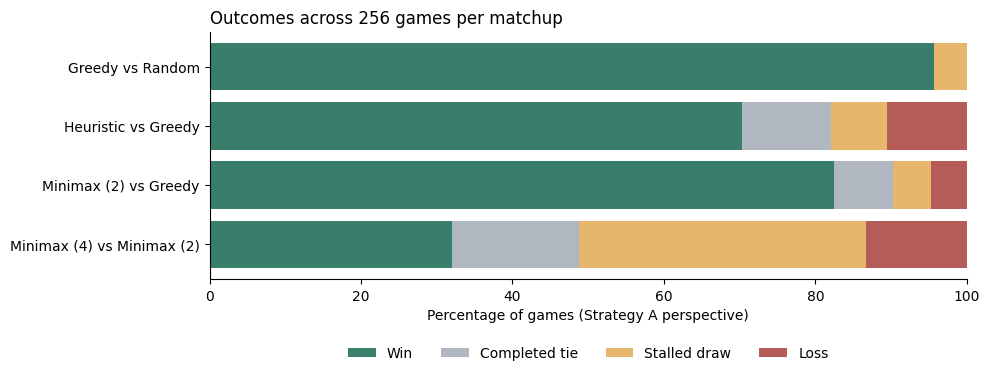

In [10]:
import matplotlib.pyplot as plt

labels = ['Greedy vs Random', 'Heuristic vs Greedy',
          'Minimax (2) vs Greedy', 'Minimax (4) vs Minimax (2)']
fig, ax = plt.subplots(figsize=(10, 4))
left = pd.Series(0.0, index=summary.index)
for column, label, color in [('wins', 'Win', '#387e6b'),
                             ('completed_ties', 'Completed tie', '#b1b7c1'),
                             ('stalled', 'Stalled draw', '#e5b66b'),
                             ('losses', 'Loss', '#b55b58')]:
    pct = 100 * summary[column] / summary['games']
    ax.barh(labels, pct, left=left, label=label, color=color)
    left += pct
ax.set_xlim(0, 100)
ax.set_xlabel('Percentage of games (Strategy A perspective)')
ax.set_title('Outcomes across 256 games per matchup', loc='left')
ax.invert_yaxis()
ax.legend(ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.22), frameon=False)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

## 8. Does moving first matter?

The original design crosses turn order and starting corner on the same boards. I compare win rates when Strategy A moves first and second (128 games per condition). The difference is measured in percentage points. This is a balanced descriptive comparison, not independent-sample inference.

In [11]:
first_mover = (games.groupby(['strategy_a','strategy_b','a_first']).outcome
               .apply(lambda x: 100*(x==1).mean()).unstack())
first_mover = first_mover.rename(columns={True:'First (%)',False:'Second (%)'})
first_mover = first_mover[['First (%)','Second (%)']]
first_mover['Difference (pp)'] = first_mover['First (%)'] - first_mover['Second (%)']
first_mover.round(1)

Strategy A,Strategy B,First (%),Second (%),Difference (pp)
greedy,random,97.7,93.8,3.9
heuristic,greedy,85.9,54.7,31.2
minimax:2,greedy,95.3,69.5,25.8
minimax:4,minimax:2,45.3,18.8,26.6


The first-player advantage is especially pronounced for the heuristic against greedy (85.9% versus 54.7%) and the four-turn strategy against two-turn minimax (45.3% versus 18.8%). The strength of a strategy should therefore be evaluated under both starting conditions, as in the balanced design used here.

## 9. Full strategy tournament

The initial comparisons do not reveal which strategy is best head-to-head. I compare all ten distinct pairs of the five configurations using the same 64 boards, both corner assignments, and both turn orders. Four original comparisons are reused and six added, for 2,560 games.

A win earns one match point, a draw half a point, and a loss zero. The mean match score (as a percentage) accounts for draws. A score of 50% indicates an even split of points. The overall ranking weights the four opponents equally.

In [12]:
from itertools import combinations
import numpy as np

STRATEGIES = ['random','greedy','heuristic','minimax:2','minimax:4']
NAMES = dict(zip(STRATEGIES,['Random','Greedy','Heuristic','Minimax (2)','Minimax (4)']))
BASE_SEEDS = range(1001,1065)


def run_match(a,b,seeds,**settings):
    return pd.DataFrame([play((a,b,seed,swap,first),**settings)
                         for seed in seeds for swap in (0,1) for first in (0,1)])


def metrics(frame):
    y = frame.outcome
    return {'Games':len(frame), 'Wins':int((y==1).sum()), 'Draws':int((y==0).sum()),
            'Losses':int((y==-1).sum()), 'Win (%)':100*(y==1).mean(),
            'Points (%)':50*(y+1).mean(), 'Stalled (%)':100*frame.stall.mean(),
            'Mean margin':frame.margin.mean()}

played = {frozenset(pair) for pair in MATCHUPS}
extra = [run_match(a,b,BASE_SEEDS) for a,b in combinations(STRATEGIES,2)
         if frozenset((a,b)) not in played]
tournament = pd.concat([games,*extra],ignore_index=True)
assert len(tournament)==2560
matrix = pd.DataFrame(np.nan,index=STRATEGIES,columns=STRATEGIES)
for (a,b),frame in tournament.groupby(['strategy_a','strategy_b']):
    matrix.loc[a,b] = metrics(frame)['Points (%)']
    matrix.loc[b,a] = 100-matrix.loc[a,b]
assert matrix.notna().sum().eq(4).all()
ranking = matrix.mean(axis=1).sort_values(ascending=False)
display(ranking.rename(index=NAMES).round(1).to_frame('Mean points (%)'))
display(matrix.rename(index=NAMES,columns=NAMES).round(1))

Strategy,Mean points (%)
Minimax (4),80.7
Minimax (2),72.6
Heuristic,61.1
Greedy,34.3
Random,1.3


Strategy,Random,Greedy,Heuristic,Minimax (2),Minimax (4)
Random,—,2.1,1.8,1.4,0.0
Greedy,97.9,—,20.1,11.1,8.2
Heuristic,98.2,79.9,—,37.9,28.5
Minimax (2),98.6,88.9,62.1,—,40.6
Minimax (4),100.0,91.8,71.5,59.4,—


Four-turn minimax earns the most match points across its four opponents (80.7%), followed by two-turn minimax (72.6%). In their direct comparison, two-turn minimax earns 62.1% of points against the original heuristic. This provides evidence for the value of anticipating the opponent beyond merely evaluating the next position. The ranking is specific to these opponents, boards, and the draw convention.

## 10. How sensitive are results to the stopping rule?

The original rule awards a draw after 12 moves without a capture, even if one player leads. This may encourage a losing player to avoid a loss by stalling. I rerun two comparisons on the same 64 boards with a 6- or 24-move draw limit, and with a 12-move limit under which the current tile leader wins. The tile-lead convention is used during search as well as when scoring the outcome. These are hypothetical alternatives, not official game rules. Stalled rates indicate unfinished boards, regardless of the awarded outcome.

In [13]:
rules = [(12,'draw'),(6,'draw'),(24,'draw'),(12,'tile lead')]
sensitivity_rows = []
for a,b in [('heuristic','greedy'),('minimax:4','minimax:2')]:
    for limit,policy in rules:
        frame = (games[(games.strategy_a==a)&(games.strategy_b==b)]
                 if (limit,policy)==(12,'draw') else
                 run_match(a,b,BASE_SEEDS,stall_limit=limit,stall_policy=policy))
        sensitivity_rows.append({'Matchup':f'{NAMES[a]} vs {NAMES[b]}',
                                 'Limit':limit,'Rule':policy,**metrics(frame)})
sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity[['Matchup','Limit','Rule','Win (%)','Points (%)','Stalled (%)','Mean margin']].round(1)

Matchup,Limit,Rule,Win (%),Points (%),Stalled (%),Mean margin
Heuristic vs Greedy,12,draw,70.3,79.9,7.4,4.6
Heuristic vs Greedy,6,draw,70.3,79.9,7.4,4.6
Heuristic vs Greedy,24,draw,70.3,79.9,7.4,4.6
Heuristic vs Greedy,12,tile lead,70.3,76.2,5.5,4.6
Minimax (4) vs Minimax (2),12,draw,32.0,59.4,37.9,2.5
Minimax (4) vs Minimax (2),6,draw,32.0,59.4,37.9,2.5
Minimax (4) vs Minimax (2),24,draw,32.0,59.4,37.9,2.5
Minimax (4) vs Minimax (2),12,tile lead,58.6,67.0,23.0,2.5


Changing the draw cutoff from 12 to 6 or 24 moves does not change win rates, match points, or stall rates in these two comparisons. Changing the way unfinished games are scored does: the four-turn strategy's win rate rises from 32.0% to 58.6%, and the stalled rate falls from 37.9% to 23.0% under the hypothetical tile-lead rule. Its match score rises from 59.4% to 67.0%. The stopping rule is therefore more than a computational detail; it changes the incentives and measured outcomes.

## 11. Can we improve the heuristic empirically?

The original coefficients $(10,2,4,1)$ were illustrative. I keep the one-turn decision rule fixed and test 12 interpretable relative weight vectors. The objective is to maximize the mean match score against greedy and two-turn minimax:

$$J(w)=\frac{1}{n}\sum_{j=1}^{n}\frac{Y_j(w)+1}{2},$$

where $Y_j$ equals +1, 0, or −1 for wins, draws, and losses. The candidate with the largest score is selected, breaking ties by fewer stalls and then listed candidate order. This finite search does not establish global optimality.

Calibration uses 48 new boards (seeds 2001–2048). Each candidate plays both fixed opponents, both corners, and both turn orders. The selected vector is tested on 64 separate boards (seeds 3001–3064) against the same opponents. This avoids evaluating on the same boards used to select weights, but does not establish generalization to unseen opponent types or human players.

In [14]:
TRAIN_SEEDS = range(2001,2049)
TEST_SEEDS = range(3001,3065)
OPPONENTS = ('greedy','minimax:2')
assert len(set(BASE_SEEDS)|set(TRAIN_SEEDS)|set(TEST_SEEDS))==176
CANDIDATES = {
    'Original':(10,2,4,1), 'Territory only':(10,0,0,0),
    'More territory':(16,2,4,1), 'Less territory':(5,2,4,1),
    'More frontier':(10,6,4,1), 'More proximity':(10,2,8,1),
    'More capture potential':(10,2,4,5), 'Balanced':(4,4,4,4),
    'Position emphasis':(5,4,8,2), 'Territory and proximity':(10,0,6,0),
    'Territory and frontier':(10,6,0,0), 'Territory and capture':(10,0,0,5),
}


def compare_weights(w,seeds):
    return pd.concat([run_match('heuristic',o,seeds,weights_a=w)
                      for o in OPPONENTS],ignore_index=True)

training = pd.DataFrame([{'Candidate':name,'Weights':w,**metrics(compare_weights(w,TRAIN_SEEDS))}
                         for name,w in CANDIDATES.items()])
training = training.sort_values(['Points (%)','Stalled (%)'],ascending=[False,True],kind='stable')
selected_name = training.iloc[0].Candidate
selected_weights = CANDIDATES[selected_name]
print(f'Selected: {selected_name}, weights {selected_weights}; {training.Games.sum():,} calibration games.')
training[['Candidate','Weights','Win (%)','Points (%)','Stalled (%)']].round(2)

Selected: More frontier, weights (10, 6, 4, 1); 4,608 calibration games.


Candidate,Weights,Win (%),Points (%),Stalled (%)
More frontier,"(10, 6, 4, 1)",47.92,69.79,37.24
More proximity,"(10, 2, 8, 1)",46.88,69.40,39.06
More capture potential,"(10, 2, 4, 5)",45.57,69.01,41.15
Less territory,"(5, 2, 4, 1)",31.25,62.50,59.38
Original,"(10, 2, 4, 1)",44.79,61.59,20.57
Territory and proximity,"(10, 0, 6, 0)",44.27,61.07,19.53
More territory,"(16, 2, 4, 1)",41.93,57.94,19.27
Balanced,"(4, 4, 4, 4)",18.23,57.42,76.56
Position emphasis,"(5, 4, 8, 2)",17.45,56.38,76.56
Territory and frontier,"(10, 6, 0, 0)",37.50,53.52,20.05


The candidate with increased frontier weight, $(10,6,4,1)$, achieves the largest calibration score (69.79% versus 61.59% for the original). The higher stall rate is already a warning: a strategy can improve its match score by avoiding losses through draws.

### 11.1 Held-out evaluation

The original and selected vectors are evaluated against the same two opponents on separate boards. I also compare the vectors head-to-head, which answers a different question from their performance against those opponents.

In [15]:
evaluation_frames = {}
heldout_rows = []
for name,w in [('Original',WEIGHTS),('Selected',selected_weights)]:
    frame = compare_weights(w,TEST_SEEDS)
    evaluation_frames[name] = frame
    for opponent,group in frame.groupby('strategy_b',sort=False):
        heldout_rows.append({'Weights':name,'Opponent':NAMES[opponent],**metrics(group)})
    heldout_rows.append({'Weights':name,'Opponent':'Both (equal weight)',**metrics(frame)})
heldout = pd.DataFrame(heldout_rows)
display(heldout[['Weights','Opponent','Games','Win (%)','Points (%)','Stalled (%)','Mean margin']].round(2))
head_to_head = run_match('heuristic','heuristic',TEST_SEEDS,weights_a=selected_weights,weights_b=WEIGHTS)
print('Selected vs original (held-out boards):')
display(pd.DataFrame([metrics(head_to_head)]).round(2))

Weights,Opponent,Games,Win (%),Points (%),Stalled (%),Mean margin
Original,Greedy,256,75.00,83.20,6.64,4.93
Original,Minimax (2),256,21.09,40.62,26.95,-1.32
Original,Both (equal weight),512,48.05,61.91,16.80,1.80
Selected,Greedy,256,75.78,85.35,15.62,5.16
Selected,Minimax (2),256,23.05,54.30,55.47,-1.93
Selected,Both (equal weight),512,49.41,69.82,35.55,1.62


Selected vs original (held-out boards):


Games,Wins,Draws,Losses,Win (%),Points (%),Stalled (%),Mean margin
256,99,131,26,38.67,64.26,41.41,-0.45


On the held-out boards, the selected vector improves the average match score from 61.91% to 69.82% (+7.91 percentage points). Its win rate rises only from 48.05% to 49.41%, while stalls increase from 16.80% to 35.55% and mean tile margin declines slightly. It wins 99 and loses 26 of 256 direct games against the original, drawing 131, and earns 64.26% of match points. This is an improvement for the chosen scoring objective, not evidence of an unambiguously superior strategy.

### 11.2 What happens when a feature is removed?

I remove one term at a time from the original evaluation without changing the other three. Each reduced model plays the same opponents on the same evaluation boards. A decrease in points suggests the omitted feature helps in combination with the original weights. This is not a causal estimate: features overlap and decisions are nonlinear. These diagnostics do not select a new model.

In [16]:
ablation_rows = [{'Removed term':'None (original)',**metrics(evaluation_frames['Original'])}]
for i,term in enumerate(['Territory (D)','Frontier (F)','Relative proximity (R)','Capture potential (M)']):
    w = tuple(0 if i==j else value for j,value in enumerate(WEIGHTS))
    ablation_rows.append({'Removed term':term,**metrics(compare_weights(w,TEST_SEEDS))})
ablation = pd.DataFrame(ablation_rows)
ablation['Change in points (pp)'] = ablation['Points (%)']-ablation.iloc[0]['Points (%)']
ablation[['Removed term','Win (%)','Points (%)','Stalled (%)','Change in points (pp)']].round(2)

Removed term,Win (%),Points (%),Stalled (%),Change in points (pp)
None (original),48.05,61.91,16.80,0.00
Territory (D),8.98,53.71,87.30,-8.20
Frontier (F),44.14,56.84,15.23,-5.08
Relative proximity (R),40.04,52.54,14.45,-9.38
Capture potential (M),43.36,58.01,17.19,-3.91


All four removals reduce the original heuristic's match score on the evaluation boards. Removing relative proximity produces the largest decrease (9.38 percentage points). Removing territory produces a particularly large increase in stalled games (87.30%) and a sharp fall in wins, even though half-credit for draws partly offsets the drop in match points. These findings support retaining positional information, but the contribution of each term depends on the other weights, the opponents, and the rules.

## 12. Takeaways and limitations

What began as an attempt to stop losing Filler games became an experiment in short-sighted optimization, strategic positioning, and the consequences of defining an objective.

- **Immediate gains are not enough.** Greedy selection defeats random play in 95.7% of the original games, but the original heuristic and two-turn minimax defeat greedy in 70.3% and 82.4%, respectively. The full tournament places four-turn minimax first under the original model.
- **Starting conditions matter.** The heuristic wins 85.9% against greedy when moving first but only 54.7% when moving second. Balancing turn order and corner is important for a fair comparison.
- **The objective matters as much as the weights.** Calibration improves match points on separate boards, but also increases stalls substantially. The alternative stopping-rule experiment demonstrates that the outcome convention affects strategy and measured performance.
- **Position has measurable value.** Removing relative proximity from the original evaluation produces the largest decrease in match points among the four feature-removal experiments. Removing territory makes stalled play especially common.

Across the original benchmark, additional tournament matches, rule sensitivity, weight calibration, held-out evaluation, direct comparison and feature-removal tests, the notebook simulates 12,032 games using 176 distinct generated boards. The reference CSV contains only the original 1,024 games; the remaining results are regenerated in the notebook. The browser demonstration retains the original rules and coefficients so its results are consistent with that reference dataset.

These are descriptive results for a modeled version of Filler. The board generator has not been validated against the original application, and the stopping conventions are not official rules. The same boards are reused across conditions, so individual games should not be treated as independent samples. The weight search examines only 12 candidates and does not establish optimality. Held-out evaluation uses the same board generator and opponent types, not human opponents or genuinely different game environments. A natural next experiment would optimize under a score that explicitly discourages stalls, then evaluate on new boards and against human players.

For now, the model has taught me something about how to approach a game. Whether I can finally beat my friend is still an open research question.